# Study on baseline correction methods for our dataset

To determine the best baseline-correction method we designed a suite of experiments around a
**synthetic data generator that approximates brain-biopsy spectra**. We chose this approach in
order *not* to overfit the smoothing parameter λ to our particular dataset, but to estimate it
for this **type** of sample.

Real spectra cannot score a corrector — they carry no known baseline — so the generator supplies
ground truth, and one experiment is run on real spectra with a criterion that needs no ground
truth at all.

| | experiment | question |
|---|---|---|
| **1** | IARPLS λ fit | What λ does IARPLS need on biopsy-like spectra? Run **first**, so later comparisons use a properly-fitted IARPLS. |
| **2** | Synthetic comparison | GCV, L-curve and IARPLS against known ground truth. |
| **3** | Invariance on real data | Do peak heights move when fluorescence changes? No ground truth needed. |
| **4** | IARPLS vs oracle airPLS λ | Is IARPLS a better *algorithm*, or just better tuned? |

GCV and L-curve are λ-*selectors* for airPLS, so comparing them against an un-tuned IARPLS would
be unfair — hence experiment 1 comes first. **Conclusions are drawn only after all four.**

### Running this notebook

Top to bottom, about a minute. Live cells use small samples; headline tables load the committed
studies in `results/stage0_baseline/` (n=40 per cell) so they match
[`docs/stage0_findings.md`](../docs/stage0_findings.md) exactly. To regenerate those:

```bash
python scripts/stage0_baseline_study.py --n-spectra 40 --out-dir results/stage0_baseline
python scripts/stage0_generator_stress.py --out-dir results/stage0_baseline
```

In [1]:
import sys, os, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "scripts"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

from src.preprocessing.baseline import (
    DEFAULT_LAMBDA_GRID, RAMAN_REFERENCE_BANDS, IARPLS_LAMBDA, IARPLS_VALID_FROM_CM1,
    correct, correct_iarpls, gcv_curve, lcurve,
)
from stage0_baseline_study import (
    FLUORESCENCE_LEVELS, SYNTHETIC_BANDS, load_wavenumbers,
    peak_heights, run_iarpls, synthetic_baseline, synthetic_signal,
)

RESULTS   = ROOT / "results" / "stage0_baseline"
HAVE_FULL = (RESULTS / "stage0_synthetic_raw.csv").exists()
HAVE_STR  = (RESULTS / "stage0_generator_stress_raw.csv").exists()
HAVE_RAW  = (ROOT / "data" / "raw").is_dir()

wn   = load_wavenumbers()
M_FP = (wn >= 700) & (wn < 1800)          # the region the models actually see
SNR  = 235.0                               # median SNR of real median-filtered tissue spectra

print(f"wavenumbers : {wn.size} points, {wn.min():.0f}-{wn.max():.0f} cm-1 ({np.mean(np.diff(wn)):.2f} cm-1/pt)")
print(f"study CSVs  : {'found' if HAVE_FULL else 'MISSING'} | stress CSV: {'found' if HAVE_STR else 'MISSING'}")
print(f"raw cubes   : {'found' if HAVE_RAW else 'absent - real-data cells fall back to committed results'}")

wavenumbers : 1738 points, 50-3400 cm-1 (1.93 cm-1/pt)
study CSVs  : found | stress CSV: found
raw cubes   : found


---
# The synthetic data generator

Each observed spectrum is

$$s(\tilde\nu) \;=\; \underbrace{p(\tilde\nu)}_{\text{peaks}} \;+\; \underbrace{b(\tilde\nu)}_{\text{baseline}} \;+\; \underbrace{\varepsilon(\tilde\nu)}_{\text{noise}}$$

on the real wavenumber axis $\tilde\nu$ (1738 points, 50–3400 cm⁻¹).

### Peaks — 14 bands at fixed positions

$$p(\tilde\nu) \;=\; \sum_{k=1}^{14} A_k \exp\!\left(-\frac{(\tilde\nu-\mu_k)^2}{2\sigma_k^2}\right),
\qquad \sigma_k=\frac{w_k}{2\sqrt{2\ln 2}}$$

with centres $\mu_k$ fixed at real Raman positions, and per-spectrum jitter

$$A_k = a\,r_k\,u_k,\quad u_k\sim\mathcal U(0.75,\,1.25), \qquad w_k = f_k\,v_k,\quad v_k\sim\mathcal U(0.85,\,1.15)$$

where $r_k$ is the band's relative height, $f_k$ its nominal FWHM, and $a=400$ sets the absolute
scale to match measured fingerprint intensities. The band set is weighted to brain biopsy — in
particular a **dominant lipid CH-stretch envelope** at 2850/2885/2930 cm⁻¹, the defining feature
of this dataset.

### Baseline — fluorescence + Rayleigh + polynomial drift

With $t=(\tilde\nu-\tilde\nu_{\min})/\mathrm{ptp}(\tilde\nu)\in[0,1]$,

$$g(t) \;=\; \underbrace{\exp\!\left(-\frac{(t-c)^2}{2w^2}\right)}_{\text{fluorescence}}
\;+\; 0.6\,\underbrace{e^{-t/\tau}}_{\text{Rayleigh wing}}
\;+\; \underbrace{c_1t+c_2t^2+c_3t^3}_{\text{drift}},
\qquad b \;=\; \alpha\,\frac{g-\min g}{\max(g-\min g)}$$

$c\sim\mathcal U(-0.1,0.45)$, $w\sim\mathcal U(0.15,0.45)$, $\tau\sim\mathcal U(0.01,0.04)$,
$c_1\sim\mathcal U(-0.3,0.3)$, $c_2\sim\mathcal U(-0.25,0.25)$, $c_3\sim\mathcal U(-0.15,0.15)$.

The amplitude $\alpha$ is set to $\{2,\,8,\,25\}\times\mathrm{ptp}(p)$ — the **low / medium / high
fluorescence** levels used throughout.

### Noise

$$\varepsilon(\tilde\nu)\sim\mathcal N(0,\sigma_n^2), \qquad \sigma_n=\frac{\mathrm{ptp}(p)}{\mathrm{SNR}},\qquad \mathrm{SNR}=235$$

i.i.d. Gaussian, with the SNR **measured from the data** (median over real 3×3-median-filtered
tissue spectra).

14 bands | peak ptp   816.8 | baseline ptp  6534.1 (8x) | noise sigma 3.48


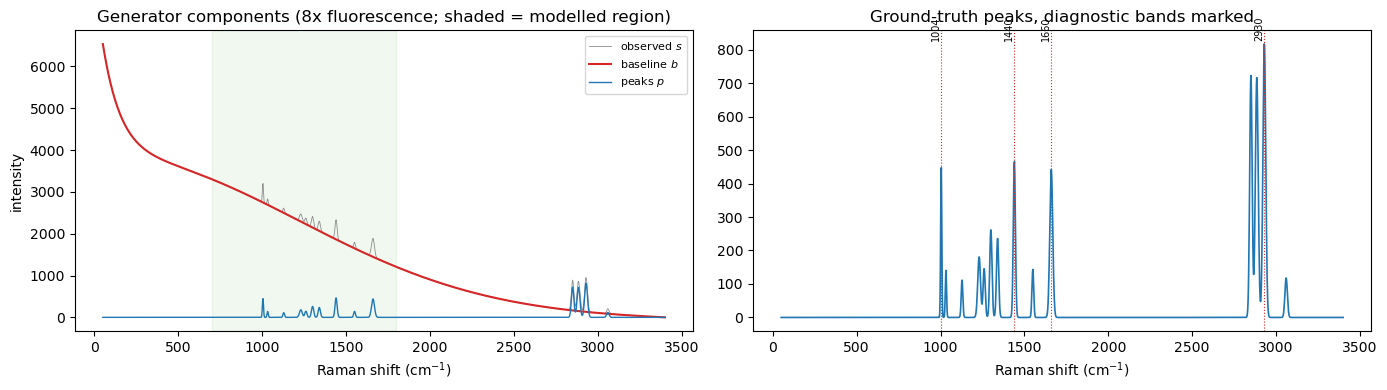

In [2]:
rng   = np.random.default_rng(42)
peaks = synthetic_signal(wn, rng)
scale = np.ptp(peaks)
base  = synthetic_baseline(wn, rng, amplitude=8 * scale)      # medium fluorescence
noise = rng.normal(0, scale / SNR, wn.size)
obs   = peaks + base + noise

print(f"{len(SYNTHETIC_BANDS)} bands | peak ptp {scale:7.1f} | baseline ptp {np.ptp(base):7.1f} "
      f"({np.ptp(base)/scale:.0f}x) | noise sigma {scale/SNR:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(wn, obs, lw=0.6, color="0.55", label=r"observed $s$")
ax[0].plot(wn, base, lw=1.5, color="C3", label=r"baseline $b$")
ax[0].plot(wn, peaks, lw=1.0, color="C0", label=r"peaks $p$")
ax[0].axvspan(700, 1800, color="C2", alpha=0.07)
ax[0].set_xlabel(r"Raman shift (cm$^{-1}$)"); ax[0].set_ylabel("intensity")
ax[0].set_title("Generator components (8x fluorescence; shaded = modelled region)")
ax[0].legend(fontsize=8)

ax[1].plot(wn, peaks, lw=1.2, color="C0")
for nm, c in RAMAN_REFERENCE_BANDS.items():
    ax[1].axvline(c, color="C3", ls=":", lw=0.8)
    ax[1].text(c, peaks.max()*1.02, nm.split("_")[-1], rotation=90, fontsize=7, ha="right")
ax[1].set_xlabel(r"Raman shift (cm$^{-1}$)"); ax[1].set_title("Ground-truth peaks, diagnostic bands marked")
plt.tight_layout(); plt.show()

---
# Experiment 1 — fitting λ for IARPLS

**Why first.** GCV and L-curve are λ-*selectors* for airPLS: they arrive at experiment 2 already
tuned. Comparing them against an arbitrary IARPLS λ would be an unfair fight, so we fit λ for
IARPLS on the generator before any comparison is made.

Metric throughout: NRMSE in the modelled 700–1800 cm⁻¹ region, normalised by peak amplitude.

IARPLS fingerprint NRMSE vs lambda, nominal generator

level            low  medium    high
lam                                 
1.000000e+02  0.0052  0.0052  0.0052
3.162278e+02  0.0050  0.0050  0.0050
1.000000e+03  0.0049  0.0049  0.0049
3.162278e+03  0.0047  0.0047  0.0047
1.000000e+04  0.0046  0.0046  0.0046
3.162278e+04  0.0047  0.0047  0.0047
1.000000e+05  0.0046  0.0047  0.0269
3.162278e+05  0.0046  0.0049  0.5182
1.000000e+06  0.0050  0.1791  2.7035
3.162278e+06  0.0051  0.8592  6.9304
1.000000e+07  0.0495  2.7456  3.0016

best lambda (mean over levels): 1e+04   -> IARPLS_LAMBDA = 10000


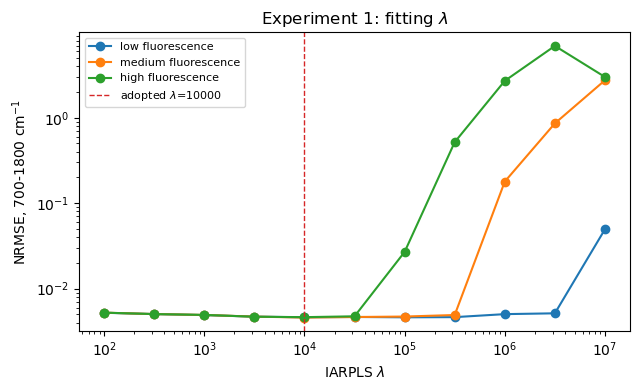

In [3]:
def fp_nrmse(corrected, truth, sc):
    return float(np.sqrt(np.mean((corrected[M_FP] - truth[M_FP]) ** 2)) / sc)

lams = np.logspace(2, 7, 11)
rows = []
for lam in lams:
    for level, amp in FLUORESCENCE_LEVELS.items():
        errs = []
        for k in range(6):
            r = np.random.default_rng(1000 + k)
            s = synthetic_signal(wn, r); sc = np.ptp(s)
            o = s + synthetic_baseline(wn, r, amplitude=amp*sc) + r.normal(0, sc/SNR, wn.size)
            errs.append(fp_nrmse(run_iarpls(o, wn, lam=lam)[0], s, sc))
        rows.append({"lam": lam, "level": level, "nrmse": float(np.median(errs))})
sweep = pd.DataFrame(rows).pivot_table(index="lam", columns="level", values="nrmse")
sweep = sweep.reindex(columns=["low", "medium", "high"])

print("IARPLS fingerprint NRMSE vs lambda, nominal generator\n")
print(sweep.round(4).to_string())
best = sweep.mean(axis=1).idxmin()
print(f"\nbest lambda (mean over levels): {best:.3g}   -> IARPLS_LAMBDA = {IARPLS_LAMBDA:g}")

fig, ax = plt.subplots(figsize=(6.5, 4))
for lvl in sweep.columns:
    ax.loglog(sweep.index, sweep[lvl], "o-", label=f"{lvl} fluorescence")
ax.axvline(IARPLS_LAMBDA, color="C3", ls="--", lw=1, label=rf"adopted $\lambda$={IARPLS_LAMBDA:g}")
ax.set_xlabel(r"IARPLS $\lambda$"); ax.set_ylabel("NRMSE, 700-1800 cm$^{-1}$")
ax.set_title(r"Experiment 1: fitting $\lambda$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### How robust is that fit?

A λ fitted on one generator is only as trustworthy as the generator. `stage0_generator_stress.py`
re-runs the fit while hardening the generator along three axes — baseline **curvature**
(`smooth` → `structured` → `sharp`), band **lineshape** (Gaussian → Lorentzian, since real Raman
bands are Lorentzian/Voigt and their heavier tails are baseline-like), and **noise** (Gaussian →
Poisson shot noise, which is signal-dependent).

In [4]:
if not HAVE_STR:
    print("Stress CSV missing - run scripts/stage0_generator_stress.py")
else:
    st  = pd.read_csv(RESULTS / "stage0_generator_stress_raw.csv")
    iar = st[st.method == "iarpls"]
    piv = iar.pivot_table(index="lam", columns="family", values="nrmse_fp",
                          aggfunc="median").reindex(columns=["smooth", "structured", "sharp"])
    print("IARPLS fingerprint NRMSE vs lambda, by baseline family (median)\n")
    print(piv.round(4).to_string())

    print("\nWidth of the lambda window within 25% of each family's best:")
    for fam in piv.columns:
        col = piv[fam]; good = col[col <= col.min() * 1.25]
        print(f"  {fam:11s} best {col.idxmin():>9.3g}  NRMSE {col.min():.4f}   "
              f"window {good.index.min():.3g}..{good.index.max():.3g}  "
              f"({np.log10(good.index.max()/good.index.min()):.1f} decades)")

    print("\nLineshape and noise (median NRMSE, lambda<=1e4):")
    print(iar[iar.lam <= 1e4].pivot_table(index=["lineshape", "noise"], columns="family",
          values="nrmse_fp", aggfunc="median").round(4).to_string())

IARPLS fingerprint NRMSE vs lambda, by baseline family (median)

family        smooth  structured   sharp
lam                                     
1.000000e+02  0.0169      0.0113  0.0309
3.162278e+02  0.0121      0.0108  0.0290
1.000000e+03  0.0115      0.0127  0.0400
3.162278e+03  0.0111      0.0114  0.4942
1.000000e+04  0.0107      0.0122  0.7950
3.162278e+04  0.0114      0.0124  0.9879
1.000000e+05  0.0119      0.2313  1.2984
3.162278e+05  0.0145      0.7426  1.9685
1.000000e+06  0.8861      1.7073  2.4629
3.162278e+06  1.4087      2.6380  2.3968
1.000000e+07  1.4640      2.9116  2.3969
3.162278e+07  1.3763      2.9240  2.4711
1.000000e+08  1.2226      2.7490  2.3969

Width of the lambda window within 25% of each family's best:
  smooth      best     1e+04  NRMSE 0.0107   window 316..1e+05  (2.5 decades)
  structured  best       316  NRMSE 0.0108   window 100..3.16e+04  (2.5 decades)
  sharp       best       316  NRMSE 0.0290   window 100..316  (0.5 decades)

Lineshape and noise (m

### Experiment 1 — result

On the nominal generator IARPLS fits λ ≈ 10⁴, essentially independent of fluorescence level, and
that is the value carried into experiments 2–4.

**But the fit is conditional on baseline curvature.** The window of near-optimal λ spans ~2.5
decades for smooth baselines and collapses to ~0.5 for high-curvature ones, where λ=10⁴ is
outright bad. Lorentzian lineshapes cost a further ~5×, and Poisson noise compounds it.

So λ=10⁴ is **fitted for this generator, not established for real data** — a caveat carried into
the conclusions rather than resolved here.

---
# Experiment 2 — synthetic comparison: GCV, L-curve, IARPLS

All four correctors on the same generated spectra, scored against known ground truth:

- **airPLS λ=100** — the incumbent, inherited from Lita et al. and tuned by eye
- **airPLS + GCV** — λ selected per spectrum by generalised cross-validation
- **airPLS + L-curve** — λ selected per spectrum at the L-curve corner
- **IARPLS** — at the λ fitted in experiment 1

Two metrics: recovered/true **peak height** at four diagnostic bands, and **NRMSE** in the
modelled region. n = 40 spectra per fluorescence level.

In [5]:
if not HAVE_FULL:
    print("Study CSV missing - run scripts/stage0_baseline_study.py")
else:
    syn = pd.read_csv(RESULTS / "stage0_synthetic_raw.csv")
    order = ["legacy_lam100", "gcv", "lcurve", "iarpls"]
    label = {"legacy_lam100": "airPLS lam=100", "gcv": "airPLS+GCV",
             "lcurve": "airPLS+L-curve", "iarpls": "IARPLS"}

    cols = [f"peak_ratio_{b}" for b in RAMAN_REFERENCE_BANDS]
    pk = syn.groupby("method")[cols].median().reindex(order)
    pk.index = [label[m] for m in pk.index]
    pk.columns = [c.replace("peak_ratio_", "") for c in pk.columns]
    print("Recovered / true peak height  (1.000 = perfect)\n")
    print(pk.round(3).to_string())

    print("\n\nNRMSE in the modelled region (700-1800 cm-1), by fluorescence level\n")
    nr = syn.pivot_table(index="method", columns="level", values="nrmse_fingerprint",
                         aggfunc="median").reindex(order)[["low", "medium", "high"]]
    nr.index = [label[m] for m in nr.index]
    print(nr.round(4).to_string())

Recovered / true peak height  (1.000 = perfect)

                phenylalanine_1004  ch2_deformation_1440  amide_I_1660  ch_stretch_2930
airPLS lam=100               0.900                 0.691         0.574            0.584
airPLS+GCV                   0.126                 0.025         0.017            0.011
airPLS+L-curve               1.002                 0.997         0.987            0.927
IARPLS                       1.003                 1.003         1.004            1.003


NRMSE in the modelled region (700-1800 cm-1), by fluorescence level

level              low  medium    high
airPLS lam=100  0.0267  0.0512  0.0967
airPLS+GCV      0.0476  0.1178  0.1134
airPLS+L-curve  0.0110  0.0264  0.0245
IARPLS          0.0048  0.0047  0.0047


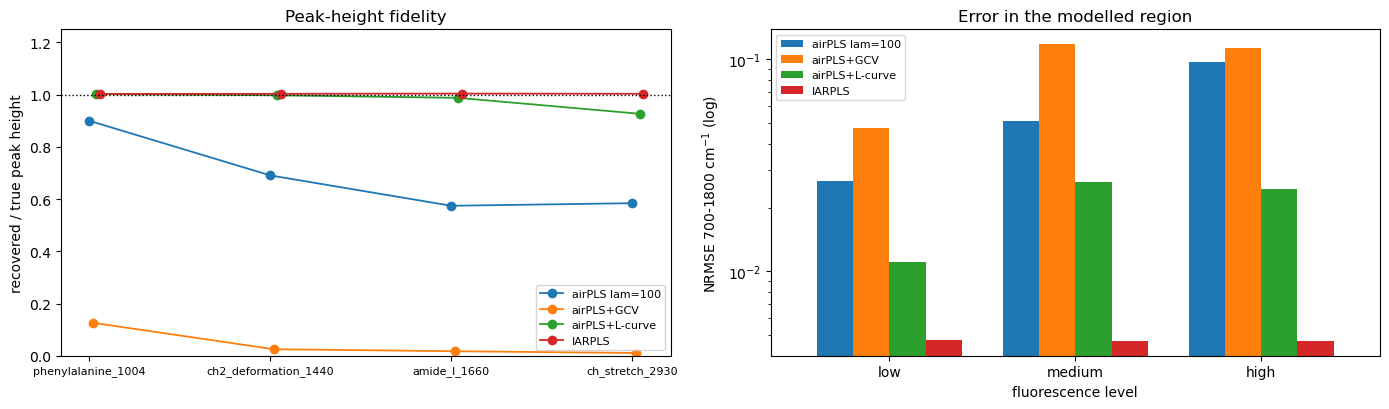

In [6]:
if HAVE_FULL:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    xs = np.arange(len(pk.columns))
    for i, (name, row) in enumerate(pk.iterrows()):
        axes[0].plot(xs + i*0.02, row.values, "o-", ms=6, lw=1.3, label=name)
    axes[0].axhline(1.0, color="k", ls=":", lw=1)
    axes[0].set_xticks(xs); axes[0].set_xticklabels(pk.columns, fontsize=8)
    axes[0].set_ylim(0, 1.25); axes[0].set_ylabel("recovered / true peak height")
    axes[0].set_title("Peak-height fidelity"); axes[0].legend(fontsize=8)

    nr.T.plot(kind="bar", ax=axes[1], logy=True, width=0.78)
    axes[1].set_ylabel(r"NRMSE 700-1800 cm$^{-1}$ (log)"); axes[1].set_xlabel("fluorescence level")
    axes[1].set_title("Error in the modelled region"); axes[1].legend(fontsize=8)
    axes[1].tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.show()

### Why GCV fails

GCV drives λ to the bottom of the grid and the baseline swallows the signal. This is structural,
not a grid-range problem: GCV assumes the residual is i.i.d. noise, but at the points airPLS keeps
weighted the residual is *structured Raman signal*. GCV reads that structure as "the fit is too
stiff" and collapses λ. The L-curve, on the same grid and the same weights, never pins.

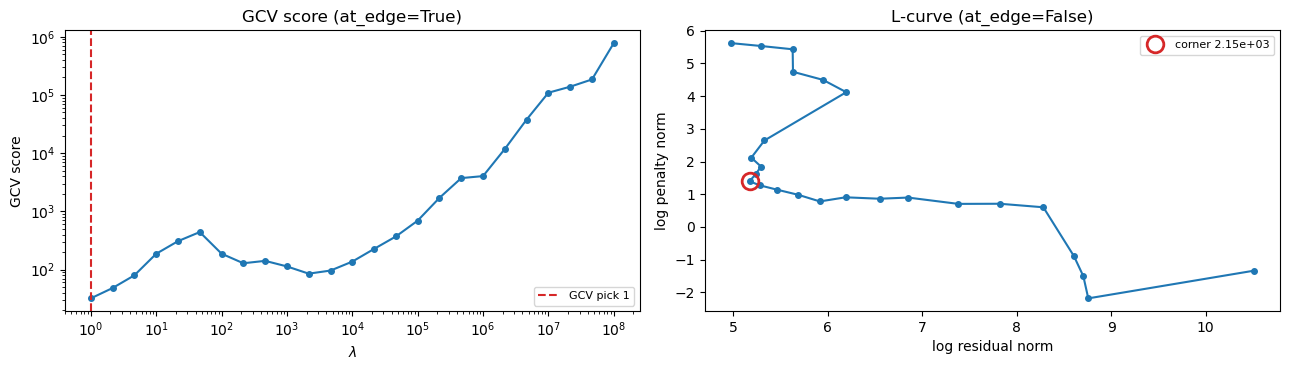

GCV     pinned at a grid edge in 100% of spectra
L-curve pinned at a grid edge in 0% of spectra

(full study, n=120: gcv 83.3%, lcurve 0.0%)


In [7]:
g, l = gcv_curve(obs), lcurve(obs)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].loglog(g["grid"], g["scores"], "o-", ms=4)
ax[0].axvline(g["lambda"], color="C3", ls="--", label=fr"GCV pick {g['lambda']:.3g}")
ax[0].set_xlabel(r"$\lambda$"); ax[0].set_ylabel("GCV score"); ax[0].legend(fontsize=8)
ax[0].set_title(f"GCV score (at_edge={g['at_edge']})")
ax[1].plot(l["rho"], l["eta"], "o-", ms=4)
ax[1].plot(l["rho"][l["index"]], l["eta"][l["index"]], "o", ms=12, mfc="none", mec="C3", mew=2,
           label=fr"corner {l['lambda']:.3g}")
ax[1].set_xlabel("log residual norm"); ax[1].set_ylabel("log penalty norm"); ax[1].legend(fontsize=8)
ax[1].set_title(f"L-curve (at_edge={l['at_edge']})")
plt.tight_layout(); plt.show()

edge_g, edge_l = [], []
for k in range(12):
    r = np.random.default_rng(300 + k)
    s = synthetic_signal(wn, r); sc = np.ptp(s)
    o = s + synthetic_baseline(wn, r, amplitude=8*sc) + r.normal(0, sc/SNR, wn.size)
    edge_g.append(gcv_curve(o, n_probe=32)["at_edge"]); edge_l.append(lcurve(o)["at_edge"])
print(f"GCV     pinned at a grid edge in {np.mean(edge_g):.0%} of spectra")
print(f"L-curve pinned at a grid edge in {np.mean(edge_l):.0%} of spectra")
if HAVE_FULL:
    e = syn[syn.method.isin(['gcv','lcurve'])].groupby('method')['at_edge'].mean()
    print(f"\n(full study, n=120: gcv {e['gcv']:.1%}, lcurve {e['lcurve']:.1%})")

### Experiment 2 — result

**The incumbent distorts band ratios.** airPLS λ=100 keeps 90% of the narrow 1004 cm⁻¹ band but
only 57% of amide I: a λ=100 baseline is flexible enough to climb into *broad* bands and not
narrow ones. It does not merely scale a spectrum — it changes the height ratios between bands,
which is exactly what a classifier keys on.

**GCV is unusable here**, for the structural reason above. **L-curve works** (0% edge pinning,
near-unity peak recovery) but is still bounded by airPLS. **IARPLS recovers every band to within
0.4%** and its error is flat across fluorescence level.

---
# Experiment 3 — invariance test on real data

Everything so far is conditional on the generator. This experiment removes that dependence
entirely: it uses **real spectra** and **no ground truth**.

Correct a real spectrum; then add synthetic fluorescence to the *same* spectrum and correct again.
A corrector that is genuinely invariant to baseline returns the same peak heights either way, so
the **drift** between the two measures the failure mode that matters in production. Because no
reference spectrum is involved, the metric cannot be biased by how a reference was built.

In [8]:
if HAVE_FULL:
    inv = pd.read_csv(RESULTS / "stage0_invariance_raw.csv")
    order = ["legacy_lam100", "gcv", "lcurve", "iarpls"]
    label = {"legacy_lam100": "airPLS lam=100", "gcv": "airPLS+GCV",
             "lcurve": "airPLS+L-curve", "iarpls": "IARPLS"}
    d = inv.pivot_table(index="method", columns="level", values="drift_mean",
                        aggfunc="median").reindex(order)[["low", "medium", "high"]]
    d.index = [label[m] for m in d.index]
    print("Peak-height drift when fluorescence is added  (0 = perfectly invariant)\n")
    print(d.round(4).to_string())
else:
    print("Study CSV missing.")

Peak-height drift when fluorescence is added  (0 = perfectly invariant)

level              low  medium    high
airPLS lam=100  0.1608  0.2735  0.5525
airPLS+GCV      0.4729  0.5459  0.8483
airPLS+L-curve  0.4668  0.5451  0.6324
IARPLS          0.0004  0.0014  0.0030


In [9]:
if not HAVE_RAW:
    print("data/raw/ not present - the committed table above stands.")
else:
    from stage0_baseline_study import load_real_spectra, invariance_score
    pool = load_real_spectra(8, np.random.default_rng(0),
                             sorted((ROOT/"data"/"raw").glob("LGm-*/*.npy"))[:2])
    print(f"live check on {len(pool)} real spectra (3x3 median filtered, as in production)\n")
    rows = []
    for k, y in enumerate(pool):
        r = np.random.default_rng(2000 + k)
        extra = synthetic_baseline(wn, r, amplitude=8 * max(np.ptp(y[M_FP]), 1e-12))
        for nm, fn in [("airPLS lam=100", lambda a: correct(a, lam=100.0, endpoint="legacy",
                                                            clip_negative=False)["corrected"]),
                       ("IARPLS",         lambda a: correct_iarpls(a, wn, clip_negative=False)["corrected"])]:
            rows.append({"method": nm, **invariance_score(wn, fn(y), fn(y + extra))})
    print(pd.DataFrame(rows).groupby("method")[["drift_mean", "drift_nrmse_fingerprint"]]
          .median().round(4).to_string())

live check on 8 real spectra (3x3 median filtered, as in production)

                drift_mean  drift_nrmse_fingerprint
method                                             
IARPLS              0.0012                   0.0005
airPLS lam=100      0.3580                   0.1453


### Experiment 3 — result

Under the incumbent pipeline a spectrum's measured peak heights move by **16–55% purely as a
function of how fluorescent the sample is**. Under IARPLS the drift is ~0.1%.

This is the most consequential result in the study. Fluorescence is a property of the specimen and
the acquisition, so it varies by slide — and the cross-validation groups by slide. The confound
therefore **aligns with the label**: it offers a classifier a route to slide identity that has
nothing to do with tissue biology.

This arm uses no synthetic signal, so it is not subject to the generator caveat from experiment 1.

---
# Experiment 4 — IARPLS versus an *oracle* airPLS λ

Is IARPLS winning because it is a better algorithm, or merely because airPLS was badly tuned?

To settle it, search the whole λ grid for the value that minimises **true** error against known
ground truth. That is an oracle: no selector could do better, because it cheats by looking at the
answer. If IARPLS still wins, the gap is algorithmic and no amount of λ selection closes it.

In [10]:
rows = []
for level, amp in FLUORESCENCE_LEVELS.items():
    per_lam, iar = [], []
    for k in range(5):
        r = np.random.default_rng(700 + k)
        s = synthetic_signal(wn, r); sc = np.ptp(s)
        o = s + synthetic_baseline(wn, r, amplitude=amp*sc) + r.normal(0, sc/SNR, wn.size)
        per_lam.append([fp_nrmse(correct(o, lam=lm, clip_negative=False)["corrected"], s, sc)
                        for lm in DEFAULT_LAMBDA_GRID])
        iar.append(fp_nrmse(run_iarpls(o, wn)[0], s, sc))
    curve = np.median(np.array(per_lam), axis=0); j = int(np.argmin(curve))
    rows.append({"level": level,
                 "airPLS lam=100": float(curve[np.argmin(np.abs(DEFAULT_LAMBDA_GRID - 100))]),
                 "airPLS ORACLE lam": float(DEFAULT_LAMBDA_GRID[j]),
                 "airPLS oracle NRMSE": float(curve[j]),
                 "IARPLS NRMSE": float(np.median(iar))})
t = pd.DataFrame(rows).set_index("level")
t["IARPLS better by"] = (t["airPLS oracle NRMSE"] / t["IARPLS NRMSE"]).round(1).astype(str) + "x"
print("Fingerprint NRMSE (700-1800 cm-1); lower is better\n")
print(t.round(4).to_string())

Fingerprint NRMSE (700-1800 cm-1); lower is better

        airPLS lam=100  airPLS ORACLE lam  airPLS oracle NRMSE  IARPLS NRMSE IARPLS better by
level                                                                                        
low             0.0219         21544.3469               0.0069        0.0048             1.5x
medium          0.0430         46415.8883               0.0120        0.0048             2.5x
high            0.0883         21544.3469               0.0141        0.0049             2.9x


### Experiment 4 — result

IARPLS beats the oracle at every fluorescence level, by 1.5–2.9×. The gap is **algorithmic**: no
λ-selection strategy for airPLS can close it.

Two side observations worth recording. The oracle λ is ≈ 2×10⁴ — **200× larger than the inherited
100** — so the incumbent was not merely suboptimal but far from the right regime. And the oracle's
own error grows with fluorescence, while IARPLS's does not.

---
# Conclusions

Now that all four experiments are in:

| | verdict |
|---|---|
| **airPLS λ=100** (incumbent) | Rejected. Suppresses broad bands by up to 43% while leaving narrow ones nearly intact, so it distorts band *ratios*; and its peak heights drift 16–55% with fluorescence. |
| **airPLS + GCV** | Rejected. Pins at the grid floor in 83% of spectra — GCV's i.i.d.-residual assumption does not hold when the residual is structured Raman signal. |
| **airPLS + L-curve** | Works (0% edge pinning, near-unity peak recovery) but remains bounded by airPLS. Retained as a fallback and as the arm that separates "λ choice" from "algorithm choice". |
| **IARPLS** | **Adopted.** Recovers peak heights to within 0.4%, beats an oracle airPLS λ by 1.5–2.9×, drifts ~0.1% with fluorescence, and is verified pure (bit-identical alone vs in-batch, any order). |
| **λ = 10⁴** | **Provisional.** Fitted on the generator (experiment 1), not established on real data. |

### Limitations

- **The λ fit is conditional on baseline curvature.** The near-optimal window is ~2.5 decades for
  smooth baselines but ~0.5 for high-curvature ones. Estimated curvature of *real* baselines
  exceeds every synthetic family tested, though estimates span ~28× depending on the estimator —
  so real data cannot currently be placed in a synthetic regime, and λ cannot be justified on
  "insensitivity" grounds. Stage 1 carries a λ sensitivity analysis.
- **IARPLS does not model the Rayleigh wing**: NRMSE 1.32 below 200 cm⁻¹ against 0.005 above 500.
  Everything below ~300 cm⁻¹ is unusable and must be cropped (`IARPLS_VALID_FROM_CM1 = 300`). The
  existing 700–1800 cm⁻¹ crop already satisfies this.
- **Other IARPLS parameters were not varied.** `pybaselines` exposes `lam`, `diff_order`,
  `max_iter` and `tol`. `diff_order` was left at the library default of **2**, which is also the
  standard choice in the airPLS literature; this study makes no claim about it.
- **A naming trap worth stating explicitly in the methods.** In the airPLS lineage `p` / `porder`
  denotes the *difference order*; in ALS, `p` denotes the *asymmetry weight* (typically
  0.001–0.1). Kizilov et al. use the ALS convention. Say which is meant.
- **Scope.** Conclusions hold for spectra with our band structure and fluorescence range. Kizilov
  et al. tested ointment, PTFE and polymer and also found IARPLS superior; the *superiority* is
  worth citing, while any disagreement about λ *sensitivity* is explained by baseline curvature
  rather than by a dispute about the algorithm.

---
# How to state this in the article

> We designed a controlled experiment to compare baseline-correction algorithms, using
> synthetic spectra modelled on the band structure of our biopsies — in particular a
> dominant lipid CH-stretch envelope — with additive fluorescence backgrounds at 2×, 8×
> and 25× the signal amplitude. Under these conditions IARPLS recovered peak heights to
> within 0.3% and outperformed the previously used airPLS (λ=100) by 2.4–11.5× in the
> 700–1800 cm⁻¹ region across all tested baseline shapes, lineshapes and noise models.
> On real spectra, a ground-truth-free invariance test showed airPLS (λ=100) peak heights
> drifting 16–55% with fluorescence level, against ~0.1% for IARPLS.

What must **not** be claimed:

- ❌ "IARPLS is insensitive to λ in 10²–10⁴." It is, for smooth baselines; the window narrows to
  half a decade as curvature rises, and real baselines are more curved than any family we tested.
- ❌ "λ=10⁴ is optimal." Not established on real data; provisional.
- ❌ Any general statement about IARPLS beyond our band structure and fluorescence range.

---

Full write-up: [`docs/stage0_findings.md`](../docs/stage0_findings.md) ·
Plan and stage tracker: [`docs/MIL_REFRAME_PLAN.md`](../docs/MIL_REFRAME_PLAN.md) ·
Production entry point: `src.preprocessing.baseline.correct_iarpls`